In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.graphics.tsaplots import plot_acf

In [2]:
df = pd.read_csv("./data/ETTh1.csv")

In [3]:
df.head()

,date,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
0,2016-07-01 00:00:00,5.827,2.009,1.599,0.462,4.203,1.340,30.531000
1,2016-07-01 01:00:00,5.693,2.076,1.492,0.426,4.142,1.371,27.787001
2,2016-07-01 02:00:00,5.157,1.741,1.279,0.355,3.777,1.218,27.787001
3,2016-07-01 03:00:00,5.090,1.942,1.279,0.391,3.807,1.279,25.044001
4,2016-07-01 04:00:00,5.358,1.942,1.492,0.462,3.868,1.279,21.948000


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17420 entries, 0 to 17419
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   date    17420 non-null  str    
 1   HUFL    17420 non-null  float64
 2   HULL    17420 non-null  float64
 3   MUFL    17420 non-null  float64
 4   MULL    17420 non-null  float64
 5   LUFL    17420 non-null  float64
 6   LULL    17420 non-null  float64
 7   OT      17420 non-null  float64
dtypes: float64(7), str(1)
memory usage: 1.4 MB


In [5]:
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17420 entries, 0 to 17419
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   date    17420 non-null  datetime64[us]
 1   HUFL    17420 non-null  float64       
 2   HULL    17420 non-null  float64       
 3   MUFL    17420 non-null  float64       
 4   MULL    17420 non-null  float64       
 5   LUFL    17420 non-null  float64       
 6   LULL    17420 non-null  float64       
 7   OT      17420 non-null  float64       
dtypes: datetime64[us](1), float64(7)
memory usage: 1.1 MB


In [7]:
print("Shape:", df.shape)

print("\nStart date:")
print(df["date"].min())

print("\nEnd date:")
print(df["date"].max())

print("\nMissing values:")
print(df.isnull().sum())

Shape: (17420, 8)

Start date:
2016-07-01 00:00:00

End date:
2018-06-26 19:00:00

Missing values:
date    0
HUFL    0
HULL    0
MUFL    0
MULL    0
LUFL    0
LULL    0
OT      0
dtype: int64


In [8]:
df.describe()

,date,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
count,17420,17420.000000,17420.000000,17420.000000,17420.000000,17420.000000,17420.000000,17420.000000
mean,2017-06-28 21:30:00,7.375141,2.242242,4.300239,0.881568,3.066062,0.856932,13.324672
min,2016-07-01 00:00:00,-22.705999,-4.756000,-25.087999,-5.934000,-1.188000,-1.371000,-4.080000
25%,2016-12-29 10:45:00,5.827000,0.737000,3.296000,-0.284000,2.315000,0.670000,6.964000
50%,2017-06-28 21:30:00,8.774000,2.210000,5.970000,0.959000,2.833000,0.975000,11.396000
75%,2017-12-27 08:15:00,11.788000,3.684000,8.635000,2.203000,3.625000,1.218000,18.079000
max,2018-06-26 19:00:00,23.643999,10.114000,17.341000,7.747000,8.498000,3.046000,46.007000
std,NaN,7.067744,2.042342,6.826978,1.809293,1.164506,0.599552,8.566946


In [9]:
train_size = 12 * 30 * 24

train_df = df.iloc[:train_size].copy()

print(train_df.shape)
print(train_df["date"].min())
print(train_df["date"].max())

(8640, 8)
2016-07-01 00:00:00
2017-06-25 23:00:00


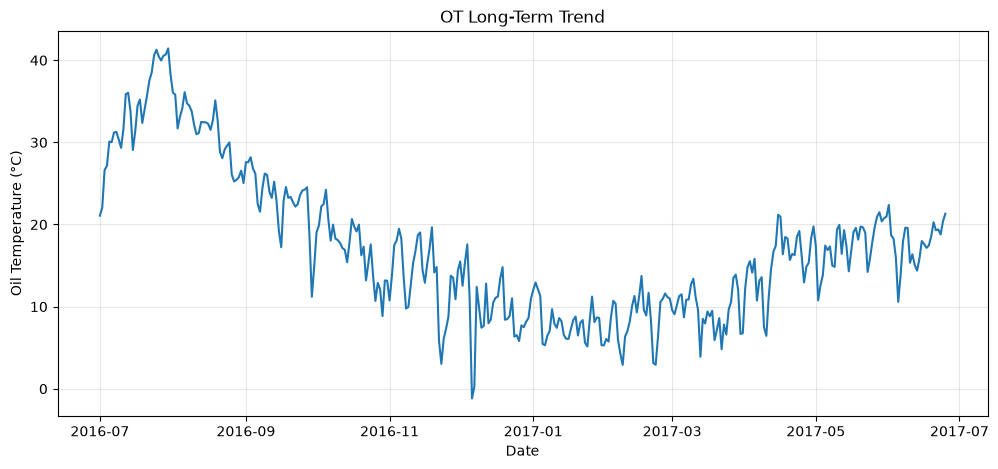

In [10]:
daily_ot = (
    train_df
    .set_index("date")["OT"]
    .resample("D")
    .mean()
)

plt.figure(figsize=(12, 5))

plt.plot(
    daily_ot.index,
    daily_ot.values
)

plt.title("OT Long-Term Trend")
plt.xlabel("Date")
plt.ylabel("Oil Temperature (°C)")

plt.grid(alpha=0.3)
plt.show()

In [11]:
train_df["hour"] = train_df["date"].dt.hour

train_df[["date", "hour", "OT"]].head()

,date,hour,OT
0,2016-07-01 00:00:00,0,30.531000
1,2016-07-01 01:00:00,1,27.787001
2,2016-07-01 02:00:00,2,27.787001
3,2016-07-01 03:00:00,3,25.044001
4,2016-07-01 04:00:00,4,21.948000


In [12]:
daily_cycle = (
    train_df
    .groupby("hour")["OT"]
    .mean()
)

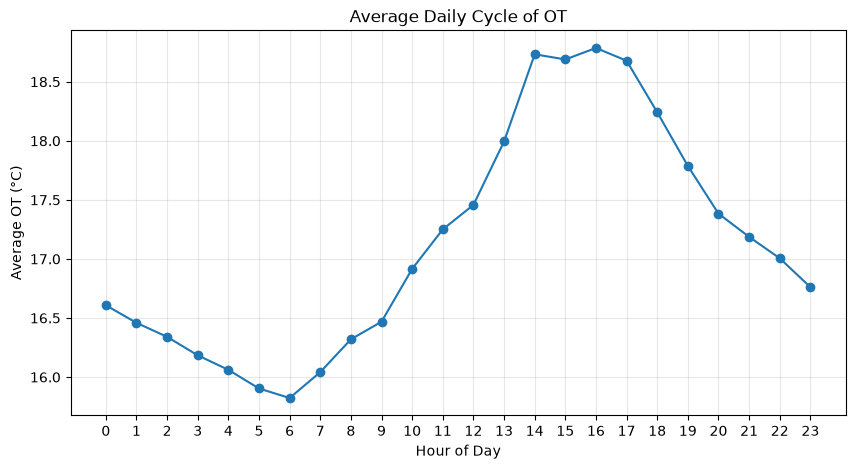

In [13]:
plt.figure(figsize=(10, 5))

plt.plot(
    daily_cycle.index,
    daily_cycle.values,
    marker="o"
)

plt.title("Average Daily Cycle of OT")

plt.xlabel("Hour of Day")
plt.ylabel("Average OT (°C)")

plt.xticks(range(0, 24))

plt.grid(alpha=0.3)
plt.show()

In [14]:
train_df["day_of_week"] = train_df["date"].dt.dayofweek

In [15]:
train_df["hour_of_week"] = (
    train_df["day_of_week"] * 24
    + train_df["hour"]
)

In [16]:
train_df[
    ["date", "day_of_week", "hour", "hour_of_week", "OT"]
].head()

,date,day_of_week,hour,hour_of_week,OT
0,2016-07-01 00:00:00,4,0,96,30.531000
1,2016-07-01 01:00:00,4,1,97,27.787001
2,2016-07-01 02:00:00,4,2,98,27.787001
3,2016-07-01 03:00:00,4,3,99,25.044001
4,2016-07-01 04:00:00,4,4,100,21.948000


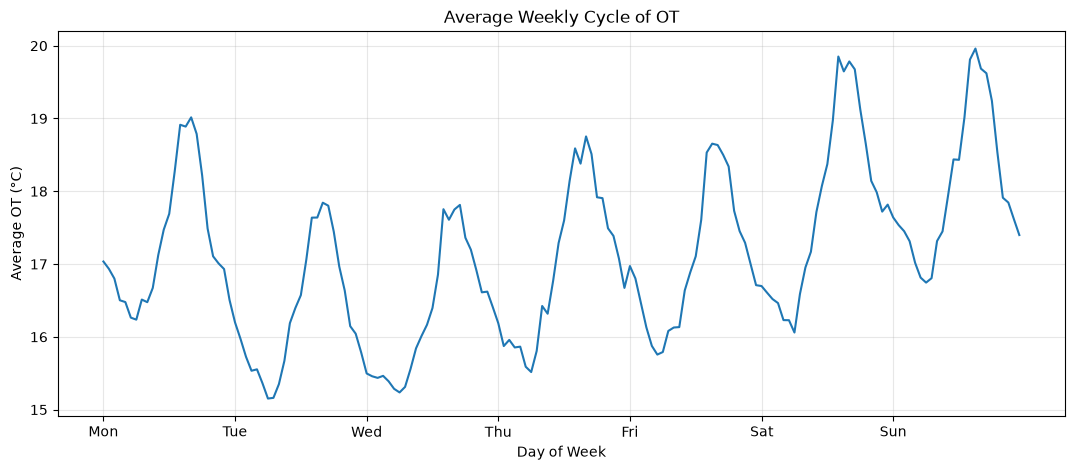

In [17]:
weekly_cycle = (
    train_df
    .groupby("hour_of_week")["OT"]
    .mean()
)

plt.figure(figsize=(13, 5))

plt.plot(
    weekly_cycle.index,
    weekly_cycle.values
)

plt.title("Average Weekly Cycle of OT")

plt.xlabel("Day of Week")
plt.ylabel("Average OT (°C)")

plt.xticks(
    [0, 24, 48, 72, 96, 120, 144],
    ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
)

plt.grid(alpha=0.3)

plt.show()

In [18]:
features = [
    "HUFL",
    "HULL",
    "MUFL",
    "MULL",
    "LUFL",
    "LULL",
    "OT"
]

corr = train_df[features].corr()

corr

,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
HUFL,1.000000,0.231962,0.983724,0.147085,0.395561,0.112120,0.199779
HULL,0.231962,1.000000,0.196454,0.925602,0.233749,0.296859,0.601444
MUFL,0.983724,0.196454,1.000000,0.142739,0.232797,0.037538,0.150241
MULL,0.147085,0.925602,0.142739,1.000000,0.048070,-0.037574,0.523530
LUFL,0.395561,0.233749,0.232797,0.048070,1.000000,0.435274,0.315764
LULL,0.112120,0.296859,0.037538,-0.037574,0.435274,1.000000,0.283408
OT,0.199779,0.601444,0.150241,0.523530,0.315764,0.283408,1.000000


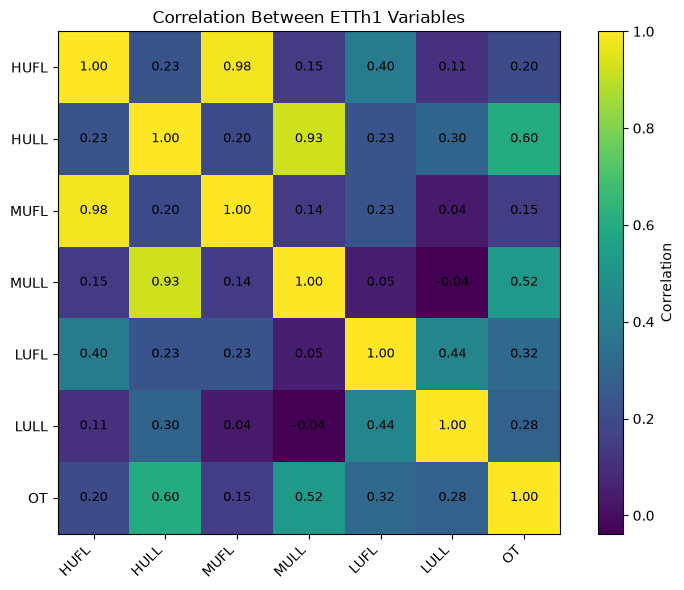

In [19]:
fig, ax = plt.subplots(figsize=(8, 6))

im = ax.imshow(corr.values)

ax.set_xticks(np.arange(len(features)))
ax.set_yticks(np.arange(len(features)))

ax.set_xticklabels(
    features,
    rotation=45,
    ha="right"
)

ax.set_yticklabels(features)

for i in range(len(features)):
    for j in range(len(features)):
        ax.text(
            j,
            i,
            f"{corr.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=9
        )

plt.colorbar(
    im,
    ax=ax,
    label="Correlation"
)

plt.title("Correlation Between ETTh1 Variables")

plt.tight_layout()
plt.show()

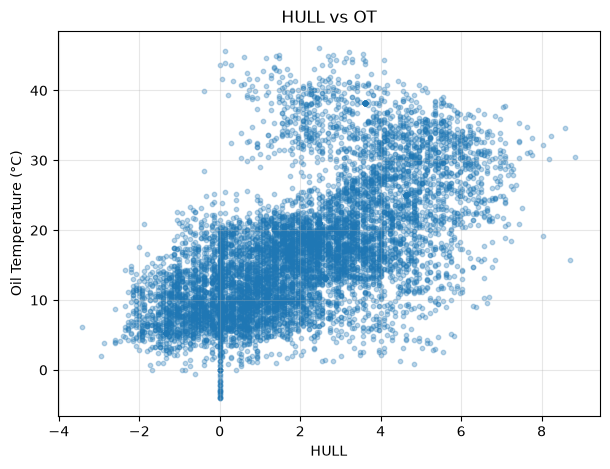

In [20]:
plt.figure(figsize=(7, 5))

plt.scatter(
    train_df["HULL"],
    train_df["OT"],
    alpha=0.3,
    s=10
)

plt.title("HULL vs OT")

plt.xlabel("HULL")
plt.ylabel("Oil Temperature (°C)")

plt.grid(alpha=0.3)

plt.show()

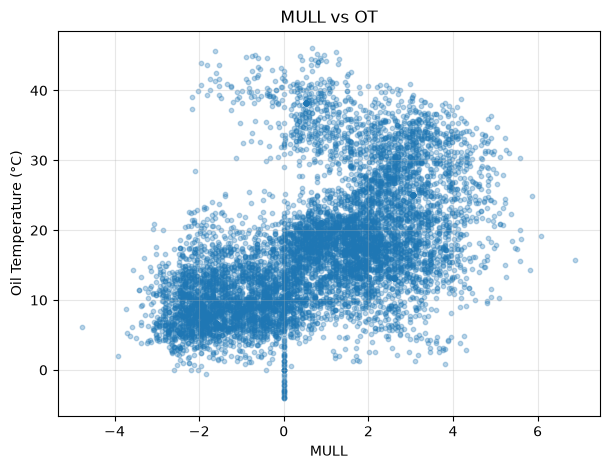

In [21]:
plt.figure(figsize=(7, 5))

plt.scatter(
    train_df["MULL"],
    train_df["OT"],
    alpha=0.3,
    s=10
)

plt.title("MULL vs OT")

plt.xlabel("MULL")
plt.ylabel("Oil Temperature (°C)")

plt.grid(alpha=0.3)

plt.show()

<Figure size 1200x500 with 0 Axes>

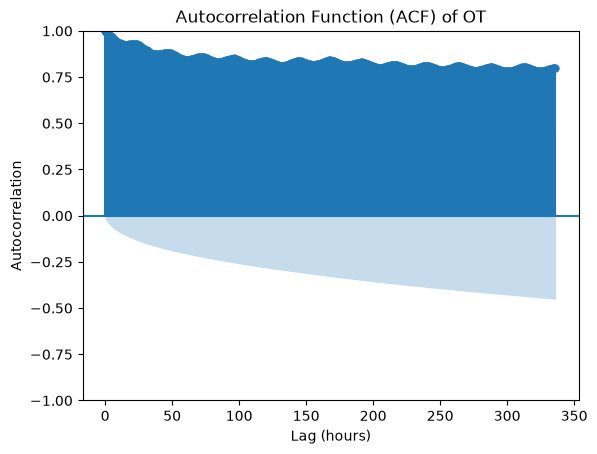

In [22]:
plt.figure(figsize=(12, 5))

plot_acf(
    train_df["OT"],
    lags=336,
    fft=True
)

plt.title("Autocorrelation Function (ACF) of OT")

plt.xlabel("Lag (hours)")
plt.ylabel("Autocorrelation")

plt.show()

In [23]:
print(
    "Lag 1:",
    train_df["OT"].autocorr(lag=1)
)

print(
    "Lag 24:",
    train_df["OT"].autocorr(lag=24)
)

print(
    "Lag 168:",
    train_df["OT"].autocorr(lag=168)
)

print(
    "Lag 336:",
    train_df["OT"].autocorr(lag=336)
)

Lag 1: 0.9932093682651917
Lag 24: 0.9286034331945647
Lag 168: 0.8530951111918328
Lag 336: 0.8388405076031451
